In [8]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

# Konfiguracja algorytmu
_MAX_STEPS = 50        
_POPULATION_SIZE = 100
_N_GENERATIONS = 150
_CROSSOVER_PROBABILITY = 0.6
_MUTATION_PROBABILITY = 0.05
SEED = 42

rng = np.random.default_rng(SEED)

In [9]:
class CliffWalkingSubject:
    def __init__(self, path: np.ndarray):
        # Akcje: 0 (Up), 1 (Right), 2 (Down), 3 (Left)
        self.path = np.asarray(path, dtype=np.int8)
        self.fitness: float | None = None

    def evaluate_fitness(self, env: gym.Env):
        if self.fitness is not None:
            return 
            
        env.reset(seed=SEED)
        total_reward = 0
        
        for action in self.path:
            _, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            
            if terminated or truncated or reward == -100:
                break
                
        self.fitness = float(total_reward)

    def __repr__(self) -> str:
        return f'Subject(fitness={self.fitness})'

In [10]:
def init_population(pop_size: int, steps: int) -> list[CliffWalkingSubject]:
    return [CliffWalkingSubject(rng.integers(0, 4, size=steps)) for _ in range(pop_size)]

def tournament_selection_max(population: list[CliffWalkingSubject], k: int = 5) -> CliffWalkingSubject:
    tournament = rng.choice(population, size=k, replace=False)
    return max(tournament, key=lambda s: s.fitness)

def single_point_crossover(parent1: CliffWalkingSubject, parent2: CliffWalkingSubject) -> tuple[CliffWalkingSubject, CliffWalkingSubject]:
    size = len(parent1.path)
    point = rng.integers(1, size - 1)
    
    child1_path = np.concatenate([parent1.path[:point], parent2.path[point:]])
    child2_path = np.concatenate([parent2.path[:point], parent1.path[point:]])
    
    return CliffWalkingSubject(child1_path), CliffWalkingSubject(child2_path)

def mutate(subject: CliffWalkingSubject, mutation_rate: float) -> CliffWalkingSubject:
    mutated_path = subject.path.copy()
    mask = rng.random(len(mutated_path)) < mutation_rate
    num_mutations = np.sum(mask)
    
    if num_mutations > 0:
        mutated_path[mask] = rng.integers(0, 4, size=num_mutations)
        
    return CliffWalkingSubject(mutated_path)

In [11]:
# Uruchomienie algorytmu i zbieranie danych do wykresów
env = gym.make('CliffWalking-v1')
population = init_population(_POPULATION_SIZE, _MAX_STEPS)

# Wstępna ocena
for subject in population:
    subject.evaluate_fitness(env)

best_history = []
average_history = []

for generation in range(_N_GENERATIONS):
    new_population = []
    
    best_current = max(population, key=lambda s: s.fitness)
    elite = CliffWalkingSubject(best_current.path.copy())
    elite.fitness = best_current.fitness
    new_population.append(elite)
    
    while len(new_population) < _POPULATION_SIZE:
        p1 = tournament_selection_max(population, k=3)
        p2 = tournament_selection_max(population, k=3)
        
        if rng.random() < _CROSSOVER_PROBABILITY:
            c1, c2 = single_point_crossover(p1, p2)
        else:
            c1 = CliffWalkingSubject(p1.path.copy())
            c2 = CliffWalkingSubject(p2.path.copy())
            
        c1 = mutate(c1, _MUTATION_PROBABILITY)
        c2 = mutate(c2, _MUTATION_PROBABILITY)
        
        c1.evaluate_fitness(env)
        c2.evaluate_fitness(env)
        
        new_population.extend([c1, c2])
        
    # Ucięcie nadmiarowych osobników
    population = new_population[:_POPULATION_SIZE]
    
    # Statystyki z generacji
    best_subj = max(population, key=lambda s: s.fitness)
    avg_fit = np.mean([s.fitness for s in population])
    
    best_history.append(best_subj.fitness)
    average_history.append(avg_fit)
    
    if generation % 10 == 0:
        print(f"Gen {generation:03d} | Best Fit: {best_subj.fitness:5.1f} | Avg: {avg_fit:6.1f}")

best_overall = max(population, key=lambda s: s.fitness)
worst_overall = min(population, key=lambda s: s.fitness)
print(f"\nTrening zakończony. Najlepszy wynik: {best_overall.fitness}")
print(f"Najgorszy wynik: {worst_overall.fitness}")
env.close()

Gen 000 | Best Fit: -43.0 | Avg:  -99.2
Gen 010 | Best Fit: -42.0 | Avg:  -68.9
Gen 020 | Best Fit: -18.0 | Avg:  -52.4
Gen 030 | Best Fit: -15.0 | Avg:  -57.3
Gen 040 | Best Fit: -15.0 | Avg:  -49.9
Gen 050 | Best Fit: -15.0 | Avg:  -59.5
Gen 060 | Best Fit: -15.0 | Avg:  -55.3
Gen 070 | Best Fit: -15.0 | Avg:  -52.9
Gen 080 | Best Fit: -15.0 | Avg:  -63.5
Gen 090 | Best Fit: -13.0 | Avg:  -36.3
Gen 100 | Best Fit: -13.0 | Avg:  -48.3
Gen 110 | Best Fit: -13.0 | Avg:  -52.0
Gen 120 | Best Fit: -13.0 | Avg:  -46.5
Gen 130 | Best Fit: -13.0 | Avg:  -52.8
Gen 140 | Best Fit: -13.0 | Avg:  -48.0

Trening zakończony. Najlepszy wynik: -13.0
Najgorszy wynik: -145.0


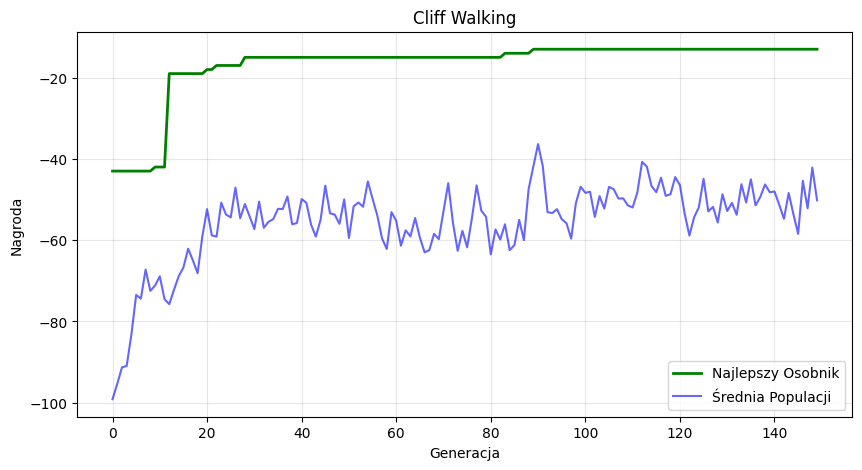

In [12]:
# Wykres zbieżności
plt.figure(figsize=(10, 5))
plt.plot(best_history, label='Najlepszy Osobnik', color='green', linewidth=2)
plt.plot(average_history, label='Średnia Populacji', color='blue', alpha=0.6)
plt.title('Cliff Walking')
plt.xlabel('Generacja')
plt.ylabel('Nagroda')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [15]:
import time

def visualise_path(selected_path):
    env_vis = gym.make('CliffWalking-v1', render_mode='human')
    env_vis.reset(seed=SEED)
    
    total_reward = 0
    
    for step_num, action in enumerate(selected_path):
        _, reward, terminated, _, _ = env_vis.step(action)
        total_reward += reward
        
        print(f"Step {step_num + 1}: Action {action} | Reward: {reward}")
        
        # Opóźnienie, żeby twoje oko nadążyło za klatkami
        time.sleep(0.3)
        
        if reward == -100 or terminated:
            break
            
    env_vis.close()

visualise_path(worst_overall.path)

Step 1: Action 0 | Reward: -1
Step 2: Action 1 | Reward: -1
Step 3: Action 1 | Reward: -1
Step 4: Action 1 | Reward: -1
Step 5: Action 1 | Reward: -1
Step 6: Action 1 | Reward: -1
Step 7: Action 1 | Reward: -1
Step 8: Action 1 | Reward: -1
Step 9: Action 0 | Reward: -1
Step 10: Action 1 | Reward: -1
Step 11: Action 1 | Reward: -1
Step 12: Action 1 | Reward: -1
Step 13: Action 1 | Reward: -1
Step 14: Action 1 | Reward: -1
Step 15: Action 3 | Reward: -1
Step 16: Action 0 | Reward: -1
Step 17: Action 0 | Reward: -1
Step 18: Action 3 | Reward: -1
Step 19: Action 0 | Reward: -1
Step 20: Action 3 | Reward: -1
Step 21: Action 2 | Reward: -1
Step 22: Action 0 | Reward: -1
Step 23: Action 1 | Reward: -1
Step 24: Action 1 | Reward: -1
Step 25: Action 0 | Reward: -1
Step 26: Action 0 | Reward: -1
Step 27: Action 3 | Reward: -1
Step 28: Action 3 | Reward: -1
Step 29: Action 0 | Reward: -1
Step 30: Action 2 | Reward: -1
Step 31: Action 0 | Reward: -1
Step 32: Action 2 | Reward: -1
Step 33: Action 0

In [16]:
visualise_path(best_overall.path)

Step 1: Action 0 | Reward: -1
Step 2: Action 1 | Reward: -1
Step 3: Action 1 | Reward: -1
Step 4: Action 1 | Reward: -1
Step 5: Action 1 | Reward: -1
Step 6: Action 1 | Reward: -1
Step 7: Action 1 | Reward: -1
Step 8: Action 1 | Reward: -1
Step 9: Action 1 | Reward: -1
Step 10: Action 1 | Reward: -1
Step 11: Action 1 | Reward: -1
Step 12: Action 1 | Reward: -1
Step 13: Action 2 | Reward: -1
